# How pylovo builds the grids

pylovo turns the buildings and streets of a postcode area into LV grids in six steps. Every step stores its result,
so this notebook can look at them one after another for one area. The documentation explains the methods behind
them: [generation pipeline](https://pylovo.readthedocs.io/en/latest/concepts/pipeline.html) and
[grid dimensioning](https://pylovo.readthedocs.io/en/latest/concepts/grid_dimensioning.html).

**Needs:** the `notebooks` extra (`uv sync --extra notebooks`). With a database in your `.env` the notebook reads the grids from it, otherwise from the example data that ship with pylovo (`data/examples`: three Bavarian postcode areas).

## Generate grids yourself

With a pylovo database set up (`uv run pylovo-setup`, [database setup](https://pylovo.readthedocs.io/en/latest/user_guide/database_setup.html)), one
command generates all LV grids of an area:

```bash
uv run pylovo-generate --plz 85256           # one or more postcode areas
uv run pylovo-generate --ags 09174115        # all postcode areas of a municipality (AGS)
uv run pylovo-generate --plz 85256 --mv      # with the MV grids
```

The settings come from `config/config_generation_lv.yaml`, and the grids are stored under its `VERSION_ID`
(notebook `05_versions`). The notebook below only reads results.

In [1]:
plz = 85256          # 80805 München (urban), 85256 Vierkirchen (semi-urban), 85307 Paunzhausen (rural)
version_id = None    # None: the version of your configuration, or of the example data

In [2]:
import matplotlib.pyplot as plt

from pylovo.examples import TutorialData
from pylovo.plotting import lv_grid, style

style.apply_style(dpi=150)
data = TutorialData(plz, version_id)
data

TutorialData(plz=85256, version 1, from the example data: no database configured)

## 1 Settlement type

pylovo first rates the area by two figures: the average number of households per building and the average distance
between buildings. Their mean, scaled between a rural and an urban threshold, gives the settlement type, and the type
decides which station ratings may be used. The grey dots are all postcode areas of the version.

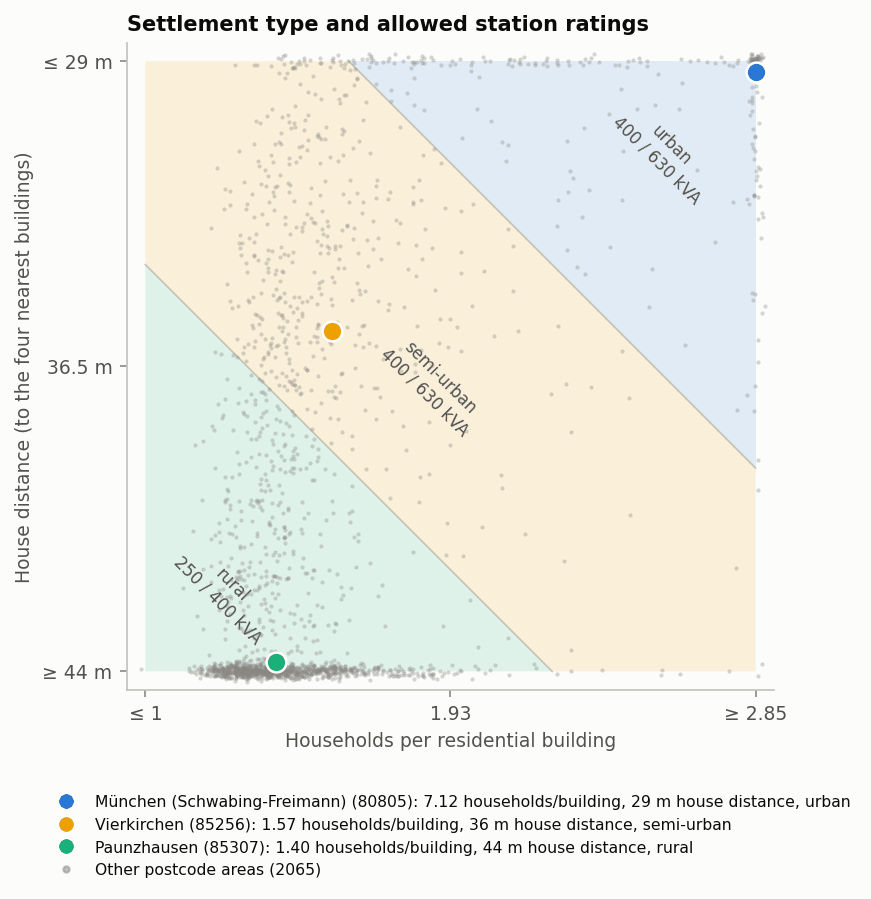

In [3]:
from pylovo.examples import EXAMPLE_AREAS

postcodes = data.postcodes()
marked = postcodes[postcodes["plz"].isin(EXAMPLE_AREAS)]
fig = lv_grid.plot_settlement_type(marked, data.parameters, context=postcodes,
                                   labels={p: f"{a['name']} ({p})" for p, a in EXAMPLE_AREAS.items()})

In [4]:
settlement = int(data.layers["postcode"]["settlement_type"].iloc[0])
ratings = data.parameters["transformer_placement"]["transformer_mapping"][str(settlement)]
print(f"Postcode area {plz}: {lv_grid.SETTLEMENT_NAMES[settlement]}, stations of {ratings} kVA")

Postcode area 85256: semi-urban, stations of [400, 630] kVA


## 2 Buildings and their loads

Every building with an address becomes a consumer, with a peak load from its use: households, commerce or public
use. Large consumers above the MV threshold are connected to the MV grid directly. Some buildings are left out,
for example sheds without an address.

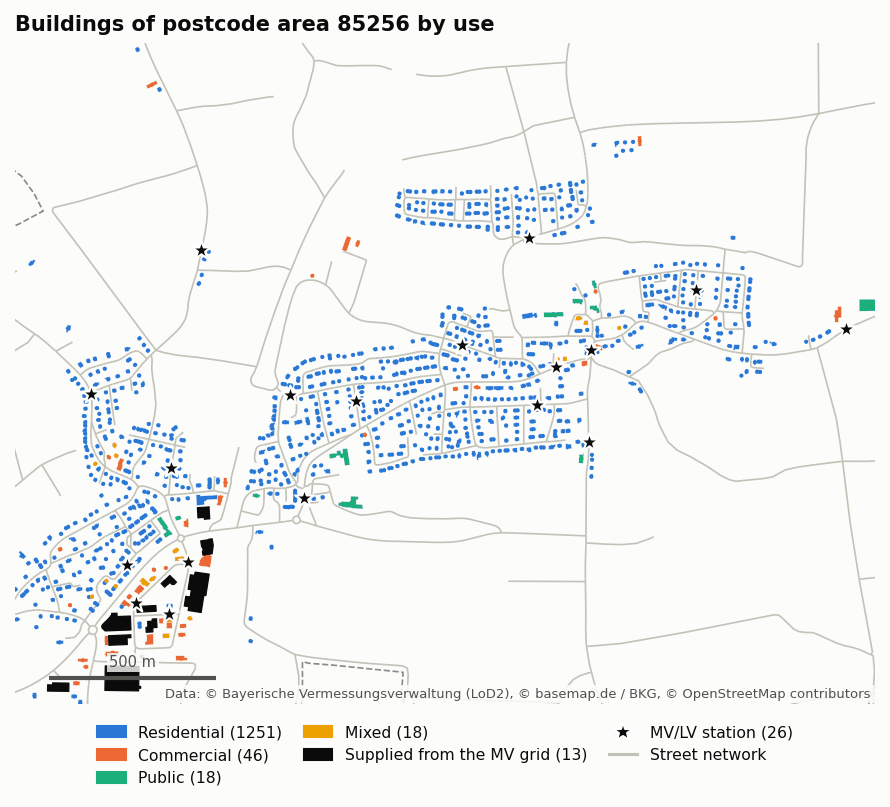

In [5]:
fig = lv_grid.plot_building_uses(data.layers, extent="core")

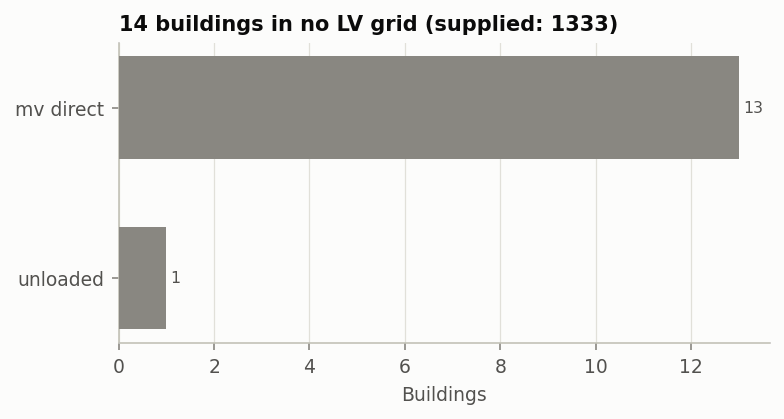

In [6]:
fig = lv_grid.plot_exclusions(data.layers["exclusions"], supplied=len(data.layers["buildings"]))

## 3 Connection to the street network

Each building is connected to the nearest street by a short connection line. Cables run only along streets and
these lines, which are the edges of the routing graph.

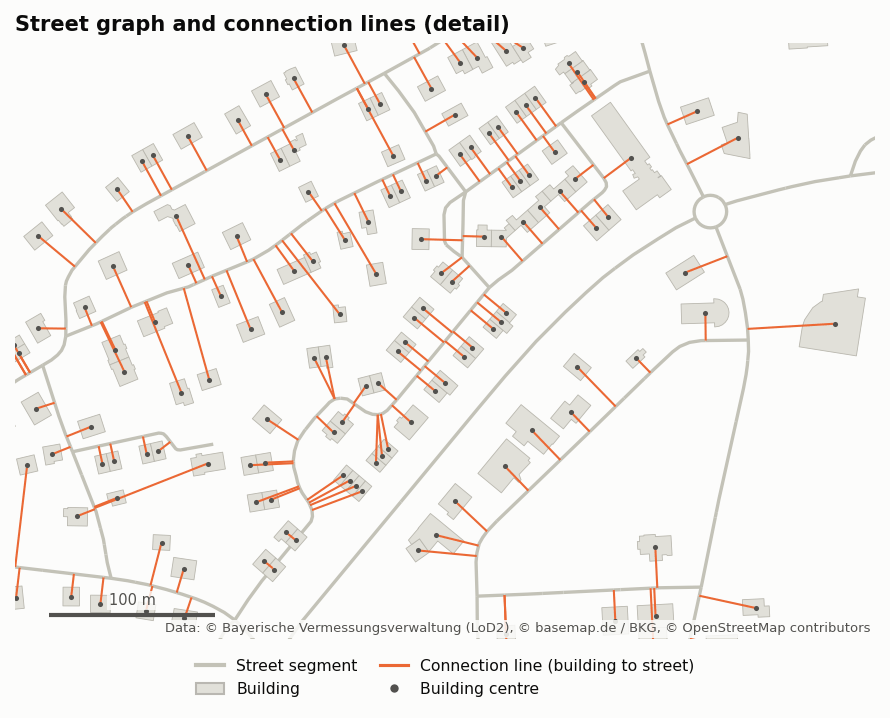

In [7]:
fig = lv_grid.plot_connections(data.layers)

## 4 Clusters and stations

k-means first splits the area into clusters (`kcid`, left) of at most `MAX_BUILDINGS_PER_KCID` buildings along the
street network. Within each, the buildings are grouped into building clusters (`bcid`, right) that one station can
supply: the load must fit the station rating and the cable distance a limit. Each building cluster gets a station
near its load centre and becomes one LV grid.

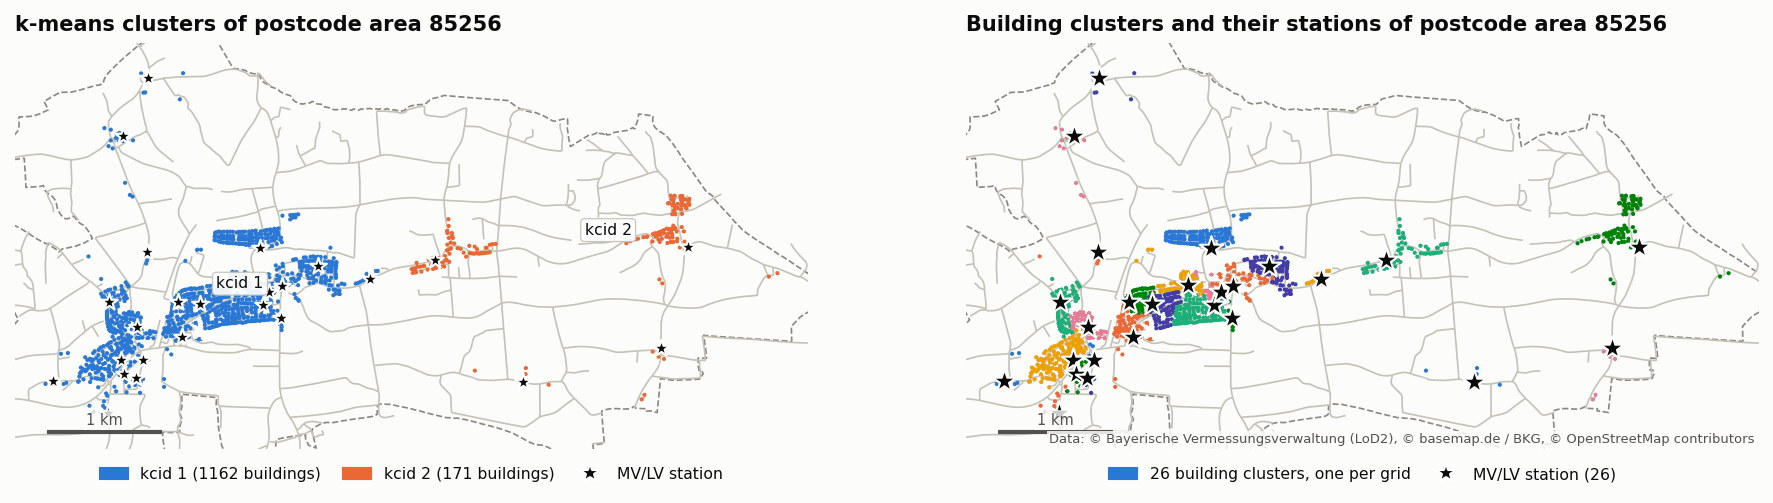

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.8))
lv_grid.plot_partition(data.layers, level="kcid", ax=axes[0], attribution="")
lv_grid.plot_partition(data.layers, level="bcid", ax=axes[1]);

## 5 Cables

Each feeder gets the cheapest cable that carries its load. If its end voltage drop is too large, the cross-section
is increased or cables are laid in parallel. The map shows which of the two rules sized each feeder section.

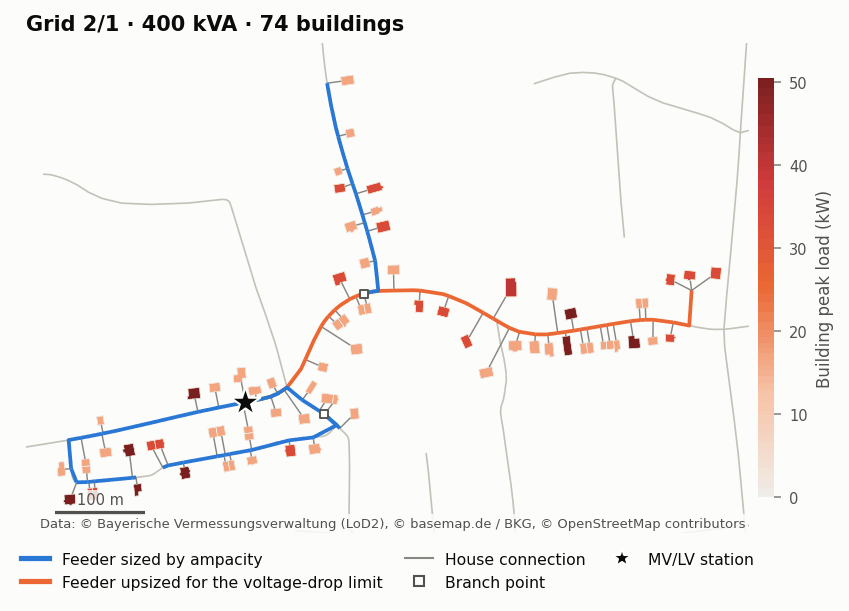

In [9]:
kcid, bcid = data.typical_grid
fig = lv_grid.plot_lv_grid(data.layers, kcid, bcid, color_by="sizing")

## 6 Checks

Last, every grid is checked: the voltage drop of its longest feeder against the design limit of the version, and a
power flow at peak load. The chart shows each grid's largest feeder drop, before and after the voltage-drop sizing.

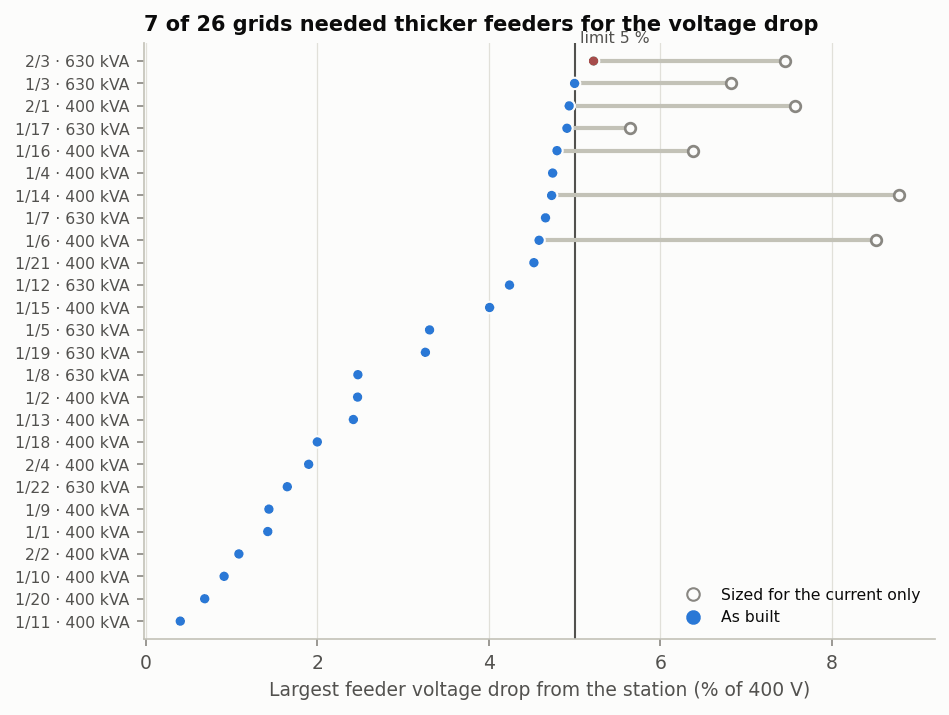

In [10]:
fig = lv_grid.plot_voltage_drop_check(data.grids, data.feeder_limit_percent)

Grids that still exceed the limit, for example with very long feeders, are stored with their power-flow status, so
they can be found and reviewed. Notebook `03_one_grid` follows one grid through its power flow.